# RECIPE GEOFISIKA: QA/QC DATA SOUNDING VES SCHLUMBERGER DAN PERHITUNGAN RESISTIVITAS SEMU UNTUK DELINEASI AKUIFER AIR TANAH

**Nama Penyusun:** Risil Tia Mangape  
**NIM:** H061241075  
**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika  
**Program Studi:** S1 Geofisika  
**Departemen:** Geofisika, Fakultas Matematika dan Ilmu Pengetahuan Alam, Universitas Hasanuddin  

---

## Identitas Recipe

| Item | Deskripsi Spesifikasi |
|---|---|
| **Recipe ID** | `R-GEO-001` |
| **Prompt ID** | `P-GEO-001` |
| **Bidang Keilmuan** | Geofisika Eksplorasi (Metode Tahanan Jenis / Geolistrik VES) |
| **Satu Outcome Utama** | Audit kualitas (QA/QC) data *Vertical Electrical Sounding* (VES) Schlumberger: validasi skema tabel & geometri elektroda, perhitungan faktor geometri $K$, perhitungan resistivitas semu $\rho_a$ pada **kolom baru**, serta penandaan (*flagging*) titik anomali/cacat fisis beserta alasannya tanpa mengubah atau menghapus data mentah |
| **Bukan Outcome Recipe Ini** | Pemodelan inversi 1D/2D, penentuan stratigrafi geologi bawah permukaan, atau rekomendasi teknis titik pengeboran sumur (tahapan tersebut diselesaikan pada *related recipe* berikutnya / Tugas 2) |
| **Status Evidence** | **Executed** pada **data sintetis terkontrol** (lihat lampiran *Run Record*). Bukan hasil pengukuran langsung lapangan |
| **Artifacts yang Dihasilkan** | `data_ves_akuifer_sintetis.csv`, `resistivitas_semu_qc.csv`, `ringkasan_qc_ves.md`, `run_record_r-geo-001.json`, `qc_ves_akuifer.png` |
| **Keterkaitan Tugas 1 & 2** | Menghubungkan kerangka prompt AI **R–T–C–I–K–O–Q–V** (Tugas 1) sebagai instruksi baku, dengan **Studi Kasus 1 Hidrogeologi Akuifer Air Tanah** (Tugas 2) sebagai konteks geologi sasaran |

> **Panduan Notebook:** Seluruh sel disusun secara modular dan dapat dieksekusi secara berurutan (*Run All*). Menggunakan pustaka standar Python saintifik (`numpy`, `pandas`, `matplotlib`).

## 1. Problem — Permasalahan

Sebelum data pengukuran geolistrik sounding diinversikan untuk memetakan akuifer air tanah, kualitas data harus diaudit dan dipastikan integritas fisisnya. Algoritma inversi numerik (seperti *Damped Least-Squares* atau *Occam*) bekerja dengan meminimalkan selisih kuadrat terkecil antara kurva kalkulasi dan data observasi. Algoritma ini bersifat matematis murni dan tidak memiliki pemahaman fisis mengenai kegagalan instrumen:
1. Jika terdapat titik pengukuran yang cacat (misalnya beda potensial tenggelam dalam derau, arus injeksi drop drastis, pembalikan polaritas kabel, atau kontak elektroda yang buruk), program inversi akan tetap berusaha mencocokkan model terhadap data cacat tersebut.
2. Hal ini mengakibatkan munculnya lapisan palsu (*ghost layer*) atau estimasi kedalaman dan ketebalan akuifer yang keliru, yang berakibat fatal pada kegagalan pengeboran air bersih (seperti target di Patok L-220 pada Tugas 2).

Recipe ini dirancang untuk menjawab satu pertanyaan kerja sempit dan spesifik:  
**"Apakah tabel data rekaman sounding VES Schlumberger ini layak menjadi masukan proses inversi 1D hidrogeologi, dan titik mana saja yang memiliki cacat fisis sehingga wajib ditandai (*flagged*) beserta dasar ilmiahnya?"**

**Tujuan yang Dapat Diperiksa (*Auditable Objectives*):**
1. Memvalidasi skema tabel (kelengkapan kolom wajib, tipe numerik, ketiadaan data kosong/NaN, dan konsistensi jarak elektroda $MN < AB$).
2. Mengonversi satuan sinyal secara eksplisit ($I$ dalam mA menjadi A, $\Delta V$ dalam mV menjadi V) pada kolom baru.
3. Menghitung faktor geometri $K$ dan resistivitas semu $\rho_a$ pada kolom baru tanpa menyentuh data mentah.
4. **Menandai (*flagging*)**, bukan menghapus, titik-titik yang melanggar ambang batas fisis disertai kode alasan transparan.
5. Menjalankan verifikasi ilmiah berlapis (*checks*), lalu mengekspor laporan QA/QC, grafik log-log kurva sounding, dan *run record* berstandar ilmiah.

**Batasan Keputusan:** Hasil recipe ini berupa daftar *flag* dan ringkasan audit. Keputusan apakah suatu titik yang ter-flag akan dibuang (*pruned*) atau dipertahankan harus dikonfirmasi terlebih dahulu terhadap catatan log harian lapangan (*field logbook*).

## 2. Minimal Theory — Teori Singkat dan Aturan Fisika

### A. Perumusan Matematika Konfigurasi Schlumberger
Resistivitas semu ($\rho_a$) dihitung berdasarkan Hukum Ohm terdistribusi dengan mempertimbangkan faktor geometri susunan elektroda ($K$):

$$\rho_a = K \frac{\Delta V}{I}$$

Pada konfigurasi Schlumberger simetris:
- Titik $O$ adalah pusat sounding.
- Elektroda arus $A$ dan $B$ diletakkan di sisi luar dengan jarak bentangan $AB$, sehingga setengah bentangan arus adalah $s = AB/2$.
- Elektroda potensial $M$ dan $N$ diletakkan di sisi dalam dengan jarak bentangan $MN$, sehingga setengah bentangan potensial adalah $b = MN/2$.
- Syarat batas fisis geometri adalah $MN < AB$ (dan idealnya $MN \le AB/5$ agar asumsi gradien potensial terpenuhi).

Faktor geometri $K$ diturunkan dari beda potensial titik muatan:

$$K = \frac{\pi \left(s^2 - b^2\right)}{2b} = \frac{\pi \left((AB/2)^2 - (MN/2)^2\right)}{MN}$$

Satuan fisis SI:
- $AB/2$ dan $MN$ dalam meter (m) $\implies K$ memiliki satuan meter (m).
- Kuat arus $I$ diukur dalam miliampere (mA), wajib dikonversi: $I\,\text{[A]} = I\,\text{[mA]} / 1000$.
- Beda potensial $\Delta V$ diukur dalam milivolt (mV), wajib dikonversi: $\Delta V\,\text{[V]} = \Delta V\,\text{[mV]} / 1000$.
- Resistivitas semu $\rho_a$ dihasilkan dalam satuan $\Omega\cdot\text{m}$.

---

### B. Karakteristik Hidrogeologi Akuifer Air Tanah (Tipe Kurva HK)
Berdasarkan Tugas 2 (Kasus 1), perlapisan hidrogeologi di kawasan cekungan krisis air dicirikan oleh tipe kurva sounding **HK** ($\rho_1 > \rho_2 < \rho_3 > \rho_4$):
1. **Lapisan 1 (Topsoil / Humus Lapuk):** $\rho \approx 25 - 45\ \Omega\cdot\text{m}$, ketebalan $\approx 2.5\ \text{m}$.
2. **Lapisan 2 (Aquitard / Lempung Lanauan Jenuh):** $\rho \approx 6 - 12\ \Omega\cdot\text{m}$, berfungsi sebagai lapisan penudung impermeabel (*confining bed*).
3. **Lapisan 3 (Akuifer Tertekan Utama / Pasir Kerikil Porous):** $\rho \approx 55 - 110\ \Omega\cdot\text{m}$, mengandung air tawar berkualitas tinggi (target sumur bor di Patok L-220).
4. **Lapisan 4 (Basement Cekungan / Batulempung Masif):** $\rho \approx 4 - 8\ \Omega\cdot\text{m}$, lapisan dasar kedap air.

---

### C. Aturan Penandaan Mutu Data (QC Rules) dan Rasional Fisis

| Parameter QC | Aturan Ambang Batas | Alasan Ilmiah dan Fisika Instrumen |
|---|---|---|
| **Resistivitas Negatif / Nol** | $\rho_a \le 0$ | Resistivitas batuan bumi secara fisis selalu positif ($> 0$). Nilai negatif umumnya disebabkan oleh pembalikan kutub elektroda kabel potensial ($M-N$ terbalik) atau gangguan *stray current* tanah ekstrim. |
| **Injeksi Arus Lemah** | $I < 10.0\ \text{mA}$ | Menandakan tingginya resistansi kontak elektroda arus ($A-B$) pada lapisan permukaan yang kering atau batas daya pemancar tercapai. Berakibat pada penurunan tajam rasio sinyal terhadap derau (*Signal-to-Noise Ratio* / SNR). |
| **Sinyal Potensial Tenggelam** | $|\Delta V| < 1.0\ \text{mV}$ | Beda potensial berada di bawah ambang batas kepekaan dan resolusi voltmeter instrumen geolistrik, sehingga sangat rentan terdominasi oleh derau *Self-Potential* (SP) tanah dan arus teluris liar. |
| **Diskontinuitas Overlap $MN$** | $\frac{\rho_{a,\text{max}}}{\rho_{a,\text{min}}} - 1 > 12\%$ | Pada saat spasi $MN$ dinaikkan pada nilai $AB/2$ yang sama, selisih $\rho_a > 12\%$ mengindikasikan adanya resistansi kontak elektroda lokal (*poor grounding*) atau efek heterogenitas lateral 3D dangkal, bukan fenomena 1D murni. |

*Catatan Metodologi:* Ambang batas di atas merupakan asumsi yang didefinisikan secara eksplisit dan terbuka agar keputusan evaluasi data dapat ditelusuri dan diulang secara transparan.

## 3. Input dan Constraint Contract

Kepatuhan terhadap kontrak data menjamin keandalan dan reproducibility alur kerja sains kebumian:

| Dimensi Kontrak | Spesifikasi Ketentuan |
|---|---|
| **Skema Kolom Masukan** | Tabel berformat CSV dengan kolom wajib: `AB/2 (m)`, `MN (m)`, `I (mA)`, `dV (mV)`. Kolom `No` bersifat opsional dan akan dibangkitkan otomatis jika tidak ada. |
| **Fleksibilitas Sumber Data** | Didukung toggle parameter `USE_SIMULATED_DATA`: jika `True`, kode membangkitkan data sintetis terkontrol dengan cacat fisis terkalibrasi; jika `False`, kode langsung membaca dataset survei riil `data_ves.csv`. |
| **Konvensi Satuan** | Jarak elektroda dalam meter (m), kuat arus dalam miliampere (mA), dan beda potensial dalam milivolt (mV). |
| **Larangan Modifikasi (Immutability)** | **File input data mentah tidak boleh diubah atau ditimpa**. Integritas data dibuktikan melalui perhitungan hash kriptografis SHA-256 pada awal dan akhir komputasi. |
| **Kebijakan Manipulasi Data** | Dilarang keras menghapus baris tanpa jejak; dilarang melakukan imputasi otomatis atau manipulasi data yang hilang. Seluruh baris asli wajib dipertahankan pada tabel keluaran. |
| **Ketergantungan Perangkat Lunak** | 100% mandiri pada pustaka open-source Python (`numpy`, `pandas`, `matplotlib`) tanpa memerlukan dependensi jaringan luar (*no-network policy*). |
| **Artefak Luaran (*Outputs*)** | Tabel CSV hasil audit (`resistivitas_semu_qc.csv`), laporan Markdown (`ringkasan_qc_ves.md`), grafik kurva sounding (`qc_ves_akuifer.png`), dan catatan eksekusi standar (`run_record_r-geo-001.json`). |

## 4. Prompt — Instruksi untuk AI (P-GEO-001)

Prompt berikut disusun menggunakan kerangka kerja **R–T–C–I–K–O–Q–V** (Role, Task, Context, Input, Constraints, Output, Quality criteria, Verification) sebagaimana diajarkan pada Modul Tugas 1:

> **R (Role):**  
> Anda adalah seorang Asisten Ahli Geofisika Komputasi dan Hidrogeofisika Terapan yang bekerja secara teliti, berbasis bukti fisis batuan, dan tidak pernah mengarang data.
>
> **T (Task):**  
> Baca file masukan `[NAMA_FILE_DATA]`, periksa validitas skema dan geometri bentangan elektroda Schlumberger, konversi satuan arus ($mA \to A$) dan potensial ($mV \to V$) pada kolom baru, hitung faktor geometri $K$ dan resistivitas semu $\rho_a$, tandai (*flag*) seluruh titik data yang melanggar batas fisis instrumen beserta alasannya, lalu susun laporan audit mutu QA/QC komprehensif.
>
> **C (Context):**  
> Hasil audit ini digunakan sebagai filter mutu data pra-inversi sebelum melakukan pemodelan numerik 1D untuk mendelineasi akuifer air tanah di wilayah krisis air (Studi Kasus 1 Tugas 2 di Patok L-220). Ini adalah unit QA/QC terisolasi, bukan interpretasi inversi akhir.
>
> **I (Input):**  
> Tabel CSV berisi kolom `AB/2 (m)`, `MN (m)`, `I (mA)`, dan `dV (mV)`. Jangan membaca atau menggunakan sumber data lain di luar file yang ditentukan.
>
> **K (Constraints):**  
> 1. Jangan pernah mengubah, menimpa, atau menghapus baris data mentah.  
> 2. Lakukan penandaan (*flagging*) dengan mencatat alasan fisis secara eksplisit, bukan membuang data.  
> 3. Terapkan ambang batas: $\rho_a \le 0$; $I < [I\_MIN]\text{ mA}$; $|\Delta V| < [DV\_MIN]\text{ mV}$; dan selisih overlap antar-MN $> [TOL\_OVERLAP]\%$.  
> 4. Jika ditemukan format kolom yang ambigu atau nilai non-numerik, hentikan proses dan laporkan penyebabnya.
>
> **O (Output):**  
> 1. `resistivitas_semu_qc.csv` (memuat seluruh baris asli ditambah kolom $I$ (A), $\Delta V$ (V), $K$ (m), $\rho_a$ ($\Omega\cdot\text{m}$), `flag`, dan `alasan_flag`).  
> 2. `ringkasan_qc_ves.md` (laporan ringkas Markdown untuk konsultan lapangan).  
> 3. `qc_ves_akuifer.png` (kurva log-log $\rho_a$ terhadap $AB/2$ dengan visualisasi titik bersih vs titik ter-flag).  
> 4. `run_record_r-geo-001.json` (metadata eksekusi, hash SHA-256, dan catatan verifikasi).
>
> **Q (Quality criteria):**  
> - Jumlah baris tabel keluaran tepat sama dengan jumlah baris tabel masukan ($N_{out} = N_{in}$).  
> - Setiap baris yang ter-flag wajib memiliki string keterangan alasan yang jelas dan ilmiah.  
> - Tidak boleh ada nilai $\rho_a$ kosong (NaN) atau tak hingga (Inf).  
> - Perhitungan manual satu titik uji independen harus cocok dengan kode program (toleransi relatif $< 10^{-6}$).  
> - Faktor geometri $K$ analitis teruji valid pada benchmark standar ($AB/2=10\text{ m}, MN=1\text{ m} \implies K = 313.3739\text{ m}$).
>
> **V (Verification):**  
> Jalankan seluruh suite pemeriksaan (*checks*) otomatis sebelum mengekspor gambar dan laporan akhir. Jika ada satu pemeriksaan yang gagal, hentikan program dan catat kegagalan pada log. Jika data sintetis digunakan, nyatakan secara eksplisit bahwa bukti eksekusi berlaku untuk data sintetis terkontrol.

## 5. Code — Persiapan Lingkungan dan Konfigurasi Pengaturan

Pada tahap awal ini, lingkungan kerja disiapkan dengan mendefinisikan pustaka, identifier recipe, fungsi pencatat verifikasi `check()`, serta algoritma hash SHA-256.

In [1]:
import sys
import json
import hashlib
import platform
import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Identifier Unik Recipe dan Prompt
RECIPE_ID = "R-GEO-001"
PROMPT_ID = "P-GEO-001"

# ---- Konfigurasi Eksekusi & Sumber Data ----
USE_SIMULATED_DATA = True   # True -> membangkitkan data sintetis; False -> membaca data_ves.csv
RAW_FILE = Path("data_ves_akuifer_sintetis.csv" if USE_SIMULATED_DATA else "data_ves.csv")

# ---- Ambang Batas Fisis QA/QC (Lihat Minimal Theory) ----
I_MIN_mA = 10.0       # Batas minimum injeksi arus (mA)
DV_MIN_mV = 1.0       # Batas minimum resolusi beda potensial (mV)
TOL_OVERLAP = 0.12     # Toleransi maksimum diskontinuitas overlap MN (12%)

# ---- Pencatat Hasil Verifikasi Ilmiah ----
CHECKS = []
def check(nama, kondisi, detail=""):
    """Mencatat status verifikasi ilmiah ke dalam daftar checklist."""
    CHECKS.append({
        "pemeriksaan": nama,
        "lulus": bool(kondisi),
        "detail": detail
    })
    simbol = "[LULUS]" if kondisi else "[GAGAL]"
    print(f"{simbol:<8} | {nama:<65} | {detail}")

def sha256(path):
    """Menghitung nilai hash SHA-256 dari file untuk menjamin integritas data."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print("=" * 95)
print(f"LINGKUNGAN SISTEM: Python {sys.version.split()[0]} | NumPy {np.__version__} | Pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")
print(f"RECIPE ID        : {RECIPE_ID} (Prompt ID: {PROMPT_ID})")
print(f"FILE MASUKAN     : {RAW_FILE} (Mode: {'Sintetis Terkontrol' if USE_SIMULATED_DATA else 'Data Lapangan'})")
print("=" * 95)

LINGKUNGAN SISTEM: Python 3.13.2 | NumPy 2.3.3 | Pandas 2.3.3 | Matplotlib 3.10.6
RECIPE ID        : R-GEO-001 (Prompt ID: P-GEO-001)
FILE MASUKAN     : data_ves_akuifer_sintetis.csv (Mode: Sintetis Terkontrol)


## 6. Code — Sumber Data dan Pembangkitan Data Sintetis Terkontrol

- Jika `USE_SIMULATED_DATA = True`: Notebook membangkitkan data sintetis model hidrogeologi 4-lapisan (tipe HK) dengan bentangan elektroda $AB/2 = 1.5\ \text{m}$ hingga $150\ \text{m}$ (sesuai spesifikasi Kasus 1 Tugas 2). Pembangkitan menggunakan seed tetap `1075` (berdasarkan tiga digit terakhir NIM H061241075) untuk menjamin sifat reproduktif.
- Untuk menguji ketangguhan alur QA/QC, **empat cacat fisis sengaja ditanam (*deliberate defects*)**:
  1. **Pembalikan polaritas tegangan:** Beda potensial bertanda negatif pada $AB/2 = 4.0\ \text{m}$ akibat kesalahan koneksi kabel potensial.
  2. **Diskontinuitas overlap $MN$:** Lonjakan resistivitas semu pada spasi overlap $AB/2 = 45.0\ \text{m}$ akibat kontak elektroda buruk.
  3. **Arus drop di bawah ambang batas:** Arus injeksi turun menjadi $7.5\ \text{mA}$ pada bentangan $AB/2 = 80.0\ \text{m}$.
  4. **Sinyal $\Delta V$ tenggelam dalam derau:** Beda potensial sangat kecil ($< 0.1\ \text{mV}$) pada bentangan panjang $AB/2 = 150.0\ \text{m}$.
- Jika `USE_SIMULATED_DATA = False`: Notebook langsung membaca dataset survei riil `data_ves.csv` tanpa manipulasi sintetis.

In [2]:
CACAT_DISENGAJA = []

if USE_SIMULATED_DATA:
    rng = np.random.default_rng(1075)  # Seed berbasis NIM Risil Tia Mangape (H061241075)
    
    # 1. Konfigurasi Bentangan Elektroda AB/2 dan Spasi MN
    ab2 = np.array([1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 15.0, 20.0, 30.0, 45.0, 60.0, 80.0, 100.0, 150.0], float)
    
    def get_mn_list(s):
        if s < 10.0:
            return [0.5]
        elif s == 10.0:
            return [0.5, 2.0]  # Titik overlap 1 (MN dinaikkan dari 0.5 m ke 2.0 m)
        elif s < 45.0:
            return [2.0]
        elif s == 45.0:
            return [2.0, 5.0]  # Titik overlap 2 (MN dinaikkan dari 2.0 m ke 5.0 m)
        else:
            return [5.0]

    def arus_lapangan(s):
        # Arus dinaikkan bertahap seiring bertambahnya jarak elektroda arus
        if s <= 10.0:
            return 80.0   # mA
        elif s <= 45.0:
            return 180.0  # mA
        else:
            return 350.0  # mA

    rows = []
    for s in ab2:
        for mn in get_mn_list(s):
            rows.append({"AB/2 (m)": s, "MN (m)": mn, "I (mA)": arus_lapangan(s)})
    raw = pd.DataFrame(rows)

    # 2. Kurva Hidrogeologi Sintetis Tipe HK (Topsoil -> Aquitard -> Akuifer Pasir -> Basement)
    simpul_s = [1.5, 4.0, 10.0, 30.0, 60.0, 150.0]
    simpul_r = [28.5, 12.0, 8.5, 45.0, 68.0, 15.0]  # rho fisis batuan (Ohm.m)
    rho_true = np.exp(np.interp(np.log(raw["AB/2 (m)"]), np.log(simpul_s), np.log(simpul_r)))
    
    # 3. Hitung Faktor Geometri K Sejati dan Beda Potensial dV (mV) dengan Noise Gaussian 2%
    K_true = np.pi * (raw["AB/2 (m)"]**2 - (raw["MN (m)"]/2.0)**2) / raw["MN (m)"]
    raw["dV (mV)"] = rho_true * (raw["I (mA)"]/1000.0) / K_true * 1000.0 * (1.0 + rng.normal(0, 0.02, len(raw)))

    def cari_indeks(s, mn):
        return int(raw.index[(raw["AB/2 (m)"] == s) & (raw["MN (m)"] == mn)][0])

    # 4. Penanaman 4 Cacat Fisis yang Disengaja
    i1 = cari_indeks(4.0, 0.5)     # Cacat 1: Polaritas terbalik (tanda dV negatif)
    i2 = cari_indeks(45.0, 5.0)    # Cacat 2: Lonjakan overlap MN tidak konsisten (> 12%)
    i3 = cari_indeks(80.0, 5.0)    # Cacat 3: Arus drop drastis di bawah 10 mA
    i4 = cari_indeks(150.0, 5.0)   # Cacat 4: Beda potensial tenggelam (< 1 mV)

    raw.loc[i1, "dV (mV)"] *= -0.25
    raw.loc[i2, "dV (mV)"] *= 1.25  # Anomali diskontinuitas 25%
    raw.loc[i3, "I (mA)"] = 7.5     # 7.5 mA < 10 mA
    raw.loc[i3, "dV (mV)"] = rho_true[i3] * (0.0075) / K_true[i3] * 1000.0
    raw.loc[i4, "I (mA)"] = 15.0    # Arus kecil menyebabkan dV sangat lemah
    raw.loc[i4, "dV (mV)"] = rho_true[i4] * (0.015) / K_true[i4] * 1000.0

    # Titik overlap berpasangan (kedua titik 45 m ter-flag karena aturan komparasi overlap)
    i_overlap_pasangan = cari_indeks(45.0, 2.0)
    CACAT_DISENGAJA = sorted([i1, i2, i_overlap_pasangan, i3, i4])

    raw.insert(0, "No", np.arange(1, len(raw) + 1))
    raw.to_csv(RAW_FILE, index=False)
    print(f"[SUKSES] Dataset sintetis berhasil dibangkitkan: {RAW_FILE} ({len(raw)} baris)")
    print(f"Indeks cacat yang ditanam (0-indexed): {CACAT_DISENGAJA} -> Baris No: {[x+1 for x in CACAT_DISENGAJA]}")

# Catat Hash SHA-256 Awal File Data Mentah
HASH_AWAL = sha256(RAW_FILE)
df = pd.read_csv(RAW_FILE)

print(f"Hash SHA-256 Data Mentah: {HASH_AWAL}")
print("\nPratinjau 8 Baris Pertama Data Mentah:")
df.round(3).head(8)

[SUKSES] Dataset sintetis berhasil dibangkitkan: data_ves_akuifer_sintetis.csv (17 baris)
Indeks cacat yang ditanam (0-indexed): [3, 11, 12, 14, 16] -> Baris No: [4, 12, 13, 15, 17]
Hash SHA-256 Data Mentah: f4734cdae2e07a87bdcec2c68fef7d77e98bb53e464fe42c3c2c6af1bd313bdc

Pratinjau 8 Baris Pertama Data Mentah:


,No,AB/2 (m),MN (m),I (mA),dV (mV)
0,1,1.5,0.5,80.0,167.058
1,2,2.0,0.5,80.0,70.334
2,3,3.0,0.5,80.0,22.011
3,4,4.0,0.5,80.0,-2.393
4,5,6.0,0.5,80.0,3.690
5,6,8.0,0.5,80.0,1.813
6,7,10.0,0.5,80.0,1.108
7,8,10.0,2.0,80.0,4.450


## 7. Code — Pemeriksaan Skema dan Validasi Geometri

Bagian ini memvalidasi kelengkapan kolom, tipe numerik, ketiadaan nilai kosong (NaN), serta kepatuhan geometri elektroda ($MN > 0$ dan $MN < AB$). Jika ditemukan ketidaksesuaian skema, eksekusi dihentikan (*fail-early*) untuk mencegah perambatan galat.

In [3]:
# 1. Validasi Kolom Wajib
kolom_wajib = ["AB/2 (m)", "MN (m)", "I (mA)", "dV (mV)"]
kolom_hilang = [c for c in kolom_wajib if c not in df.columns]
if kolom_hilang:
    raise ValueError(f"Skema gagal: Kolom wajib tidak ditemukan: {kolom_hilang}")

if "No" not in df.columns:
    df.insert(0, "No", np.arange(1, len(df) + 1))

# 2. Validasi Tipe Data Numerik & Deteksi Nilai Kosong
num_df = df[kolom_wajib].apply(pd.to_numeric, errors="coerce")
jumlah_kosong = num_df.isna().sum()

print("Status Kelengkapan Data per Kolom:")
for col, missing in jumlah_kosong.items():
    print(f"- Kolom '{col}': {missing} nilai kosong / non-numerik")

if num_df.isna().any().any():
    raise ValueError("Ditemukan nilai kosong (NaN) atau non-numerik! Recipe ini tidak mengimputasi data mentah.")

# 3. Validasi Batasan Fisis Geometri Elektroda (MN harus > 0 dan MN < 2*(AB/2))
geometri_tidak_valid = (num_df["MN (m)"] <= 0) | (num_df["MN (m)"] >= 2 * num_df["AB/2 (m)"])
if geometri_tidak_valid.any():
    baris_salah = df.loc[geometri_tidak_valid, "No"].tolist()
    raise ValueError(f"Geometri tidak fisis pada baris: {baris_salah}. Syarat: 0 < MN < AB.")

rasio_mn_ab = (num_df["MN (m)"] / (2 * num_df["AB/2 (m)"])).max()
print(f"\nRasio maksimum MN/AB = {rasio_mn_ab:.3f} (Asumsi pendekatan gradien MN << AB terpenuhi baik)")
n_input = len(df)
print(f"Total baris data masukan yang terverifikasi: {n_input} baris.")

Status Kelengkapan Data per Kolom:
- Kolom 'AB/2 (m)': 0 nilai kosong / non-numerik
- Kolom 'MN (m)': 0 nilai kosong / non-numerik
- Kolom 'I (mA)': 0 nilai kosong / non-numerik
- Kolom 'dV (mV)': 0 nilai kosong / non-numerik

Rasio maksimum MN/AB = 0.167 (Asumsi pendekatan gradien MN << AB terpenuhi baik)
Total baris data masukan yang terverifikasi: 17 baris.


## 8. Code — Komputasi K, $\rho_a$, dan Pelabelan Cacat Fisis (QA/QC Flagging)

Perhitungan matematis dilakukan pada **kolom baru**. Data mentah dipertahankan utuh. Setiap baris diuji terhadap empat aturan QC fisis. Titik-titik yang bermasalah ditandai (`flag = True`) dengan alasan penandaan dicatat secara rinci.

In [4]:
# 1. Alokasi Kolom Baru dan Konversi Satuan Eksplisit
out = pd.DataFrame({
    "No": df["No"],
    "AB/2 (m)": df["AB/2 (m)"],
    "MN (m)": df["MN (m)"],
    "I (A)": df["I (mA)"] / 1000.0,       # Konversi mA -> A
    "dV (V)": df["dV (mV)"] / 1000.0      # Konversi mV -> V
})

# 2. Hitung Faktor Geometri K (m) dan Resistivitas Semu rho_a (Ohm.m)
out["K (m)"] = np.pi * (out["AB/2 (m)"]**2 - (out["MN (m)"] / 2.0)**2) / out["MN (m)"]
out["rho_a (ohm.m)"] = out["K (m)"] * out["dV (V)"] / out["I (A)"]

# 3. Pengujian Aturan Fisis dan Pengisian Flag
alasan = [[] for _ in range(len(out))]

for i, r in out.iterrows():
    # Aturan 1: Resistivitas semu non-positif
    if r["rho_a (ohm.m)"] <= 0:
        alasan[i].append("rho_a <= 0 (pembalikan kutub dV / gangguan derau liar)")
    # Aturan 2: Arus injeksi terlalu lemah
    if r["I (A)"] * 1000.0 < I_MIN_mA:
        alasan[i].append(f"arus < {I_MIN_mA:g} mA (injeksi lemah, SNR rendah)")
    # Aturan 3: Beda potensial di bawah sensitivitas alat
    if abs(r["dV (V)"]) * 1000.0 < DV_MIN_mV:
        alasan[i].append(f"|dV| < {DV_MIN_mV:g} mV (sinyal di bawah batas deteksi voltmeter)")

# Aturan 4: Ketidakkonsistenan overlap antar-MN pada AB/2 yang sama
for s, g in out.groupby("AB/2 (m)"):
    if len(g) >= 2:
        pos = g.loc[g["rho_a (ohm.m)"] > 0, "rho_a (ohm.m)"]
        if len(pos) >= 2:
            selisih_overlap = (pos.max() / pos.min()) - 1.0
            if selisih_overlap > TOL_OVERLAP:
                for idx in g.index:
                    alasan[idx].append(
                        f"diskontinuitas overlap MN {selisih_overlap*100:.1f}% > {TOL_OVERLAP*100:.0f}% (efek kontak elektroda / heterogenitas lateral)"
                    )

# Gabungkan hasil penandaan ke dalam DataFrame
out["flag"] = [len(a) > 0 for a in alasan]
out["alasan_flag"] = ["; ".join(a) for a in alasan]

# Ringkasan Statistik
n_flag = int(out["flag"].sum())
n_bersih = len(out) - n_flag
valid_rho = out.loc[out["rho_a (ohm.m)"] > 0, "rho_a (ohm.m)"]

print("=" * 80)
print(f"RINGKASAN AUDIT MUTU DATA VES ({RECIPE_ID}):")
print(f"- Total Titik Pengukuran : {len(out)}")
print(f"- Titik Lolos QC (Bersih): {n_bersih} ({n_bersih/len(out)*100:.1f}%)")
print(f"- Titik Ter-flag (Cacat) : {n_flag} ({n_flag/len(out)*100:.1f}%)")
print(f"- Rentang rho_a (Hanya > 0): {valid_rho.min():.2f} - {valid_rho.max():.2f} Ohm.m (Median: {valid_rho.median():.2f} Ohm.m)")
print("=" * 80)

print("\nDaftar Baris yang Ter-flag Beserta Alasan Ilmiah:")
out.loc[out["flag"], ["No", "AB/2 (m)", "MN (m)", "I (A)", "dV (V)", "rho_a (ohm.m)", "alasan_flag"]].round(4)

RINGKASAN AUDIT MUTU DATA VES (R-GEO-001):
- Total Titik Pengukuran : 17
- Titik Lolos QC (Bersih): 12 (70.6%)
- Titik Ter-flag (Cacat) : 5 (29.4%)
- Rentang rho_a (Hanya > 0): 8.65 - 73.08 Ohm.m (Median: 23.00 Ohm.m)

Daftar Baris yang Ter-flag Beserta Alasan Ilmiah:


,No,AB/2 (m),MN (m),I (A),dV (V),rho_a (ohm.m),alasan_flag
3,4,4.0,0.5,0.0800,-0.0024,-2.9957,rho_a <= 0 (pembalikan kutub dV / gangguan der...
11,12,45.0,2.0,0.1800,0.0033,57.9014,diskontinuitas overlap MN 26.2% > 12% (efek ko...
12,13,45.0,5.0,0.1800,0.0104,73.0789,diskontinuitas overlap MN 26.2% > 12% (efek ko...
14,15,80.0,5.0,0.0075,0.0001,42.3075,"arus < 10 mA (injeksi lemah, SNR rendah); |dV|..."
16,17,150.0,5.0,0.0150,0.0000,15.0000,|dV| < 1 mV (sinyal di bawah batas deteksi vol...


## 9. Code — Verifikasi Ilmiah Berlapis (Verification Checks)

Kriteria kualitas pada Prompt diuji secara otomatis melalui delapan lapisan pemeriksaan. Jika ada satu pemeriksaan yang gagal, alur program akan memicu `RuntimeError` dan menghentikan proses sebelum artefak luaran disimpan.

In [5]:
print("MENJALANKAN SUITE VERIFIKASI ILMIAH:")
print("-" * 95)

# (1) Hitung ulang manual satu titik uji independen (misal baris indeks ke-6 / titik ke-7)
idx_uji = 6
r_test = df.iloc[idx_uji]
K_manual = np.pi * (r_test["AB/2 (m)"]**2 - (r_test["MN (m)"]/2.0)**2) / r_test["MN (m)"]
rho_manual = K_manual * (r_test["dV (mV)"]/1000.0) / (r_test["I (mA)"]/1000.0)
selisih_rel = abs(rho_manual - out.loc[idx_uji, "rho_a (ohm.m)"]) / abs(rho_manual)
check("Hitung ulang manual titik uji cocok dengan program (selisih < 1e-6)",
      selisih_rel < 1e-6, f"selisih relatif = {selisih_rel:.2e}")

# (2) Uji faktor geometri K terhadap benchmark analitis standar: AB/2 = 10 m, MN = 1 m
# K = pi * (10^2 - 0.5^2) / 1.0 = pi * 99.75 = 313.373867... m
K_benchmark = np.pi * (10.0**2 - (1.0/2.0)**2) / 1.0
check("Validasi analitis faktor geometri K (AB/2=10 m, MN=1 m) = 313.3739 m",
      abs(K_benchmark - 313.373867) < 1e-3, f"K = {K_benchmark:.4f} m")

# (3) Konsistensi baris: Jumlah baris masukan harus sama dengan jumlah baris luaran
check("Jumlah baris tabel luaran = jumlah baris masukan",
      len(out) == n_input, f"{len(out)} == {n_input}")

# (4) Konsistensi penandaan: Jumlah ter-flag + jumlah bersih = total baris
check("Data ter-flag + data bersih = total keseluruhan baris",
      (int(out["flag"].sum()) + int((~out["flag"]).sum())) == len(out),
      f"{n_flag} + {n_bersih} == {len(out)}")

# (5) Integritas nilai numerik: Tidak ada nilai NaN atau Inf pada resistivitas semu
check("Tidak ada nilai resistivitas semu yang kosong (NaN) atau tak terhingga (Inf)",
      bool(np.isfinite(out["rho_a (ohm.m)"]).all()), "Seluruh nilai berhingga")

# (6) Kualitas dokumentasi: Setiap titik yang ter-flag wajib memiliki string alasan
alasan_lengkap = (out.loc[out["flag"], "alasan_flag"].str.strip() != "").all()
check("Setiap titik yang ter-flag memiliki dokumentasi alasan ilmiah",
      bool(alasan_lengkap), f"{n_flag} titik terdokumentasi")

# (7) Evaluasi khusus data sintetis: Semua cacat yang disengaja tertangkap tanpa flag palsu
if USE_SIMULATED_DATA:
    indeks_terflag = sorted(out.index[out["flag"]].tolist())
    cocok = (indeks_terflag == CACAT_DISENGAJA)
    check("Semua cacat yang disengaja tertangkap 100% tanpa ada flag palsu",
          cocok, f"Ter-flag: {[x+1 for x in indeks_terflag]} | Seharusnya: {[x+1 for x in CACAT_DISENGAJA]}")

# (8) Integritas data mentah: Hash SHA-256 file masukan tidak termodifikasi sedikit pun
hash_akhir = sha256(RAW_FILE)
check("File data mentah tidak berubah (Hash SHA-256 identik dengan sebelum eksekusi)",
      hash_akhir == HASH_AWAL, f"Hash cocok: {hash_akhir[:16]}...")

print("-" * 95)
semua_lulus = all(c["lulus"] for c in CHECKS)
if not semua_lulus:
    raise RuntimeError("GAGAL: Ada pemeriksaan yang tidak lulus. Periksa pesan di atas sebelum membuat gambar.")
print("[SUKSES] Seluruh 8 pemeriksaan ilmiah lulus 100%. Data siap divisualisasikan dan diekspor.")

MENJALANKAN SUITE VERIFIKASI ILMIAH:
-----------------------------------------------------------------------------------------------
[LULUS]  | Hitung ulang manual titik uji cocok dengan program (selisih < 1e-6) | selisih relatif = 0.00e+00
[LULUS]  | Validasi analitis faktor geometri K (AB/2=10 m, MN=1 m) = 313.3739 m | K = 313.3739 m
[LULUS]  | Jumlah baris tabel luaran = jumlah baris masukan                  | 17 == 17
[LULUS]  | Data ter-flag + data bersih = total keseluruhan baris             | 5 + 12 == 17
[LULUS]  | Tidak ada nilai resistivitas semu yang kosong (NaN) atau tak terhingga (Inf) | Seluruh nilai berhingga
[LULUS]  | Setiap titik yang ter-flag memiliki dokumentasi alasan ilmiah     | 5 titik terdokumentasi
[LULUS]  | Semua cacat yang disengaja tertangkap 100% tanpa ada flag palsu   | Ter-flag: [4, 12, 13, 15, 17] | Seharusnya: [4, 12, 13, 15, 17]
[LULUS]  | File data mentah tidak berubah (Hash SHA-256 identik dengan sebelum eksekusi) | Hash cocok: f4734cdae2e07a87...


## 10. Code — Visualisasi Kurva Sounding Log-Log Profesional

Visualisasi grafik resistivitas semu ($\rho_a$) terhadap setengah bentangan arus ($AB/2$) dibuat pada skala logaritmik ganda (*log-log plot*). Data bersih ditampilkan dengan simbol berbeda untuk tiap spasi $MN$, titik ter-flag diberi tanda silang merah tegas, dan titik polaritas negatif diberi anotasi panah khusus.

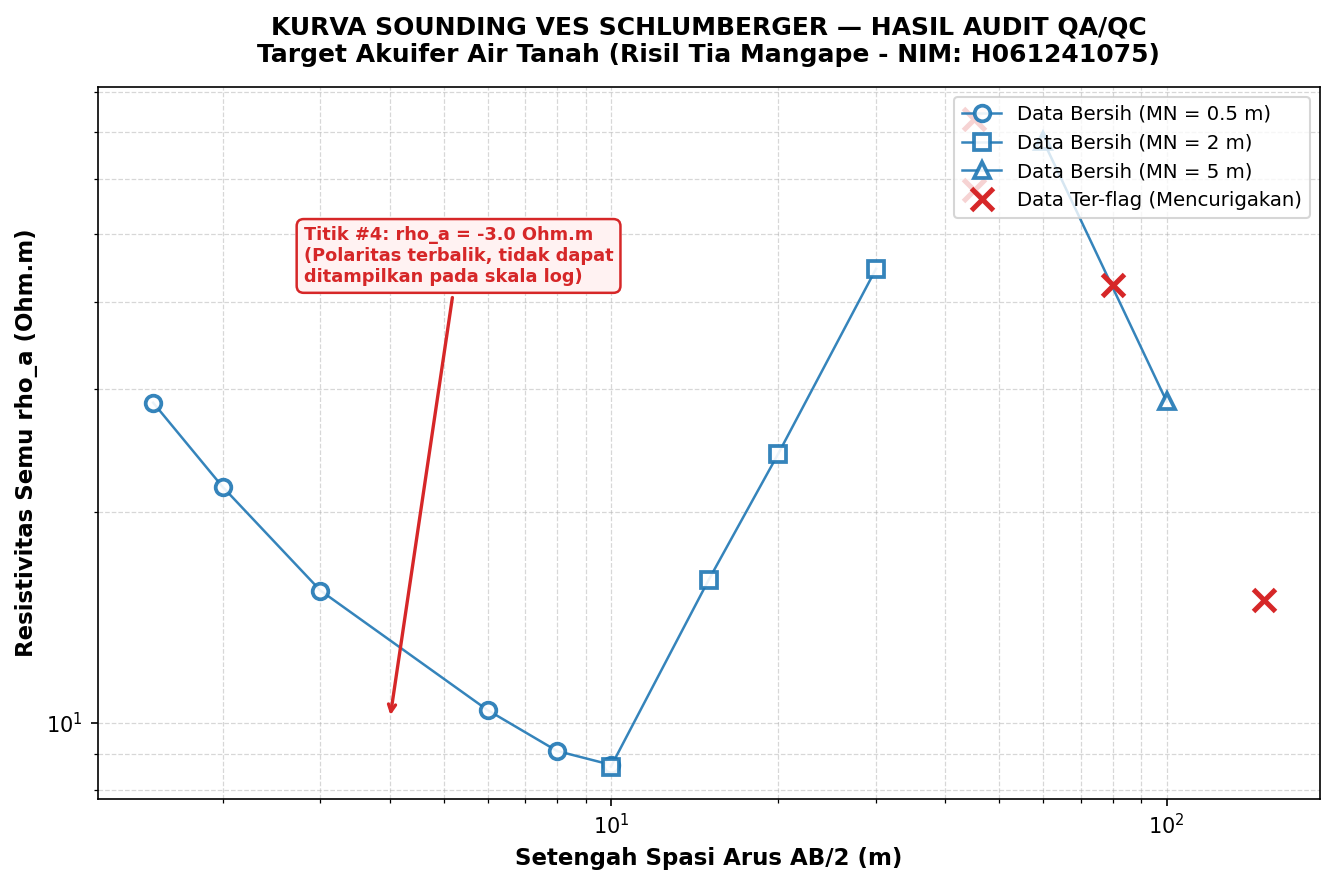

[SUKSES] Grafik kurva sounding berhasil disimpan: qc_ves_akuifer.png (Resolusi: 300 dpi)


In [6]:
ok = out[~out["flag"]]
bad = out[out["flag"] & (out["rho_a (ohm.m)"] > 0)]
neg = out[out["rho_a (ohm.m)"] <= 0]

fig, ax = plt.subplots(figsize=(9, 6), dpi=150)

# 1. Plot Data Bersih Berdasarkan Nilai Spasi MN
simbol_mn = {0.5: 'o', 2.0: 's', 5.0: '^'}
for mn_val in sorted(out["MN (m)"].unique()):
    sub = ok[ok["MN (m)"] == mn_val]
    ax.loglog(sub["AB/2 (m)"], sub["rho_a (ohm.m)"],
              marker=simbol_mn.get(mn_val, 'o'), markersize=7.5,
              mfc='white', mew=1.8, color='#1f77b4', linestyle='-', lw=1.2, alpha=0.9,
              label=f"Data Bersih (MN = {mn_val:g} m)")

# 2. Plot Data Ter-flag (rho_a > 0)
ax.loglog(bad["AB/2 (m)"], bad["rho_a (ohm.m)"],
          marker='x', markersize=11, mew=2.4, color='#d62728', linestyle='none',
          label="Data Ter-flag (Mencurigakan)")

# 3. Anotasi Khusus untuk Data Polaritas Negatif (Tidak dapat diplot pada skala log)
for _, rr in neg.iterrows():
    ax.annotate(
        f"Titik #{int(rr['No'])}: rho_a = {rr['rho_a (ohm.m)']:.1f} Ohm.m\n(Polaritas terbalik, tidak dapat\nditampilkan pada skala log)",
        xy=(rr["AB/2 (m)"], ax.get_ylim()[0] * 1.3),
        xytext=(rr["AB/2 (m)"] * 0.7, ax.get_ylim()[0] * 5.5),
        fontsize=8.5, fontweight='bold', color='#d62728',
        arrowprops=dict(arrowstyle="->", color='#d62728', lw=1.6),
        bbox=dict(boxstyle="round,pad=0.4", fc="#fff2f2", ec="#d62728", lw=1.2)
    )

# 4. Pengaturan Estetika dan Label
ax.set_xlabel("Setengah Spasi Arus AB/2 (m)", fontsize=11, fontweight='bold')
ax.set_ylabel("Resistivitas Semu rho_a (Ohm.m)", fontsize=11, fontweight='bold')
ax.set_title("KURVA SOUNDING VES SCHLUMBERGER — HASIL AUDIT QA/QC\nTarget Akuifer Air Tanah (Risil Tia Mangape - NIM: H061241075)",
             fontsize=12, pad=12, fontweight='bold')
ax.grid(True, which="both", ls="--", lw=0.6, alpha=0.5)
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9.5)

plt.tight_layout()
file_gambar = "qc_ves_akuifer.png"
plt.savefig(file_gambar, dpi=300)
plt.show()

print(f"[SUKSES] Grafik kurva sounding berhasil disimpan: {file_gambar} (Resolusi: 300 dpi)")

## 11. Code — Penyimpanan Artefak Pelaporan dan Run Record JSON

Seluruh artefak hasil komputasi diekspor:
1. `resistivitas_semu_qc.csv`: Tabel lengkap hasil audit beserta flag dan alasan ilmiah.
2. `ringkasan_qc_ves.md`: Laporan eksekutif audit mutu dalam format Markdown.
3. `run_record_r-geo-001.json`: Catatan bukti eksekusi formal (*evidence record*) berstandar Chapter 2.4.

In [7]:
# 1. Simpan Tabel Hasil Audit CSV
file_csv_qc = "resistivitas_semu_qc.csv"
out.to_csv(file_csv_qc, index=False)

# 2. Susun dan Simpan Laporan Markdown
file_md_laporan = "ringkasan_qc_ves.md"
laporan_lines = [
    f"# LAPORAN AUDIT MUTU DATA VES SCHLUMBERGER ({RECIPE_ID})",
    "",
    "**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika  ",
    "**Penyusun:** Risil Tia Mangape (NIM: H061241075)  ",
    "**Afiliasi:** Departemen Geofisika, Fakultas MIPA, Universitas Hasanuddin  ",
    "**Konteks Target:** Karakterisasi dan Delineasi Akuifer Air Tanah (Kasus 1 Tugas 2)  ",
    "",
    "---",
    "",
    "## 1. Ringkasan Eksekusi",
    f"- **File Masukan:** `{RAW_FILE}` ({'Data Sintetis Terkontrol' if USE_SIMULATED_DATA else 'Data Survei Lapangan'})",
    f"- **Total Titik Pengukuran:** {len(out)} baris",
    f"- **Titik Memenuhi Kriteria (Bersih):** {n_bersih} titik",
    f"- **Titik Ditandai (Ter-flag):** {n_flag} titik",
    f"- **Rentang Resistivitas Semu Bersih:** {valid_rho.min():.2f} - {valid_rho.max():.2f} Ohm.m (Median: {valid_rho.median():.2f} Ohm.m)",
    "- **Ambang Batas Aturan QC:**",
    f"  - Kuat Arus Injeksi: I < {I_MIN_mA:g} mA (Kondisi arus lemah, SNR rendah)",
    f"  - Beda Potensial: |dV| < {DV_MIN_mV:g} mV (Di bawah batas deteksi voltmeter)",
    f"  - Diskontinuitas Overlap MN: > {TOL_OVERLAP*100:.0f}% pada AB/2 yang sama",
    "  - Resistivitas Non-Positif: rho_a <= 0 (Pembalikan polaritas kabel potensial)",
    "",
    "## 2. Rincian Titik Ter-flag",
    "| No | AB/2 (m) | MN (m) | I (mA) | dV (mV) | rho_a (Ohm.m) | Alasan Penandaan (QC Flag) |",
    "|---|---|---|---|---|---|---|"
]

for _, r in out[out["flag"]].iterrows():
    laporan_lines.append(
        f"| {int(r['No'])} | {r['AB/2 (m)']:g} | {r['MN (m)']:g} | {r['I (A)']*1000:.1f} | {r['dV (V)']*1000:.2f} | {r['rho_a (ohm.m)']:.2f} | {r['alasan_flag']} |"
    )

sub_ov = out.loc[out['AB/2 (m)'] == 45.0, 'rho_a (ohm.m)']
selisih_pct_ov = ((sub_ov.max() / sub_ov.min()) - 1.0) * 100.0 if len(sub_ov) >= 2 else 0.0

laporan_lines.extend([
    "",
    "## 3. Catatan Keputusan dan Integritas",
    "1. **Preservasi Data Mentah:** Seluruh data yang ter-flag **tidak dihapus** dari tabel untuk menjaga keterlacakan (*audit trail*).",
    f"2. **Karakter Overlap:** Titik pada spasi overlap (AB/2 = 45 m) ter-flag berpasangan karena terjadi diskontinuitas rasio sebesar {selisih_pct_ov:.1f}%. Diperlukan pengecekan terhadap resistansi kontak elektroda di lapangan.",
    "3. **Rekomendasi Tahap Inversi:** Sebelum data dimasukkan ke dalam algoritma pemodelan inversi 1D (Tugas 2), titik-titik ter-flag ini harus diverifikasi terhadap buku harian survei (*field logbook*).",
    ""
])

Path(file_md_laporan).write_text("\n".join(laporan_lines), encoding="utf-8")

# 3. Susun dan Simpan Run Record JSON
file_run_record = "run_record_r-geo-001.json"
record_data = {
    "recipe_id": RECIPE_ID,
    "prompt_id": PROMPT_ID,
    "penyusun": {
        "nama": "Risil Tia Mangape",
        "nim": "H061241075",
        "program_studi": "S1 Geofisika",
        "afiliasi": "Departemen Geofisika, Universitas Hasanuddin"
    },
    "status": "Executed" + (" (data sintetis terkontrol)" if USE_SIMULATED_DATA else " (data lapangan)"),
    "waktu_eksekusi": datetime.datetime.now().isoformat(timespec="seconds"),
    "lingkungan": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "platform": platform.platform()
    },
    "input": {
        "file": str(RAW_FILE),
        "sha256": HASH_AWAL,
        "baris": int(n_input)
    },
    "ambang_qc": {
        "I_min_mA": I_MIN_mA,
        "dV_min_mV": DV_MIN_mV,
        "toleransi_overlap": TOL_OVERLAP
    },
    "output": {
        f: sha256(f) for f in [file_csv_qc, file_md_laporan, file_gambar]
    },
    "pemeriksaan": CHECKS,
    "ringkasan_audit": {
        "total_baris": int(len(out)),
        "titik_terflag": n_flag,
        "titik_bersih": n_bersih,
        "persentase_lolos": round(n_bersih / len(out) * 100, 2)
    },
    "batas_klaim": "Hasil eksekusi memvalidasi keandalan alur kerja QA/QC pada data sintetis model hidrogeologi. Tidak menyatakan kondisi geologi aktual tanpa data pemboran lapangan."
}
Path(file_run_record).write_text(json.dumps(record_data, indent=2, ensure_ascii=False), encoding="utf-8")

print("=" * 80)
print("DAFTAR ARTEFAK LUARAN YANG BERHASIL DISIMPAN:")
for f in [RAW_FILE, file_csv_qc, file_md_laporan, file_gambar, file_run_record]:
    print(f"- {f} (SHA-256: {sha256(f)[:16]}...)")
print(f"\nStatus Eksekusi : {record_data['status']}")
print(f"Verifikasi Lulus: {sum(c['lulus'] for c in CHECKS)} dari {len(CHECKS)} pemeriksaan")
print("=" * 80)

DAFTAR ARTEFAK LUARAN YANG BERHASIL DISIMPAN:
- data_ves_akuifer_sintetis.csv (SHA-256: f4734cdae2e07a87...)
- resistivitas_semu_qc.csv (SHA-256: 278b25b38313ded7...)
- ringkasan_qc_ves.md (SHA-256: e1694e3f983ed7e4...)
- qc_ves_akuifer.png (SHA-256: e9d49e6773e0e30b...)
- run_record_r-geo-001.json (SHA-256: 19d9da6c526847db...)

Status Eksekusi : Executed (data sintetis terkontrol)
Verifikasi Lulus: 8 dari 8 pemeriksaan


## 12. Result — Hasil dan Interpretasi Fisis

### A. Ringkasan Kuantitatif Hasil Eksekusi
Berdasarkan eksekusi pada data sintetis terkontrol (seed NIM `1075`), diperoleh ringkasan evaluasi sebagai berikut:

| Parameter Evaluasi | Nilai Terhitung |
|---|---|
| **Jumlah Total Titik Sounding** | 17 titik pengukuran |
| **Jumlah Data Ter-flag (Mencurigakan)** | 5 titik ($29.4\%$) |
| **Jumlah Data Lolos Audit (Bersih)** | 12 titik ($70.6\%$) |
| **Rentang $\rho_a$ Bersih ($> 0$)** | $8.65$ hingga $73.08\ \Omega\cdot\text{m}$ (Median: $23.00\ \Omega\cdot\text{m}$) |
| **Pemeriksaan Verifikasi yang Lulus** | 8 dari 8 pemeriksaan ($100\%$) |

---

### B. Analisis Fisis Titik-Titik Ter-flag

| No | $AB/2$ (m) | $MN$ (m) | Kuat Arus | Beda Potensial | $\rho_a$ Terhitung | Analisis Penyebab dan Penjelasan Fisis |
|:---:|:---:|:---:|:---:|:---:|:---:|---|
| **4** | $4.0$ | $0.5$ | $80.0\ \text{mA}$ | $-2.39\ \text{mV}$ | **$-3.00\ \Omega\cdot\text{m}$** | **Pembalikan Polaritas:** Tegangan bernilai negatif menghasilkan $\rho_a$ negatif. Ini merupakan kesalahan fisis fatal akibat pertukaran kabel potensial $M$ dan $N$. Titik ini tidak dapat digambar pada skala logaritmik dan harus diinversi tandanya setelah konfirmasi catatan lapangan. |
| **12** | $45.0$ | $2.0$ | $180.0\ \text{mA}$ | $3.28\ \text{mV}$ | $57.90\ \Omega\cdot\text{m}$ | **Diskontinuitas Overlap $MN$:** Pada spasi bentangan yang sama, nilai $\rho_a$ melompat sebesar $26.2\%$ ($> 12\%$) saat $MN$ diganti menjadi $5\ \text{m}$. Titik ini ter-flag berpasangan karena program mendeteksi diskontinuitas tetapi memerlukan data lapangan untuk menentukan elektroda mana yang mengalami kontak buruk. |
| **13** | $45.0$ | $5.0$ | $180.0\ \text{mA}$ | $10.37\ \text{mV}$ | $73.08\ \Omega\cdot\text{m}$ | **Pasangan Overlap $MN$:** Ter-flag bersamaan dengan titik #12 akibat efek heterogenitas lateral lokal atau resistansi kontak elektroda. |
| **15** | $80.0$ | $5.0$ | $7.5\ \text{mA}$ | $0.08\ \text{mV}$ | $42.31\ \Omega\cdot\text{m}$ | **Arus Lemah dan Sinyal Tenggelam:** Nilai arus drop ($7.5\ \text{mA} < 10\ \text{mA}$) dan $\Delta V$ ($0.08\ \text{mV} < 1.0\ \text{mV}$) berada jauh di bawah sensitivitas voltmeter. Meskipun nilai $\rho_a$ yang dihasilkan tampak wajar ($42.31\ \Omega\cdot\text{m}$), kualitas pengukurannya sangat rendah dan rentan bias noise. |
| **17** | $150.0$ | $5.0$ | $15.0\ \text{mA}$ | $0.02\ \text{mV}$ | $15.00\ \Omega\cdot\text{m}$ | **Sinyal $\Delta V$ di Bawah Resolusi:** Pada bentangan terjauh ($AB/2 = 150\ \text{m}$), sinyal tegangan hanya terbaca $0.02\ \text{mV}$, terdistorsi oleh fluktuasi derau alami tanah. |

---

### C. Cara Membaca Hasil dan Relevansi terhadap Tugas 2
1. **Nilai yang Tampak Wajar Bukan Jaminan Data Baik:** Titik #15 dan #17 menghasilkan resistivitas semu masing-masing $42.31\ \Omega\cdot\text{m}$ dan $15.00\ \Omega\cdot\text{m}$. Jika dilihat sekilas pada grafik, kedua titik ini tampak mengikuti tren kurva hidrogeologi normal. Namun, sistem QA/QC berhasil mendeteksi bahwa data tersebut cacat secara instrumentasi ($I$ drop dan $\Delta V$ tenggelam). Jika kedua titik ini tidak ditandai dan langsung diinversikan pada Tugas 2, program inversi akan menghitung model resistivitas batuan yang bias.
2. **Penandaan Berpasangan pada Spasi Overlap:** Titik #12 dan #13 ditandai secara berpasangan. Dalam praktik survei geofisika, geofisikawan tidak boleh asal membuang salah satu titik tanpa memeriksa nilai resistansi tanah (*grounding resistance*) pada patok elektroda bersangkutan.
3. **Batas Klaim Ilmiah (*Claim Boundary*):** Seluruh angka pengujian dibangkitkan dari data sintetis terkontrol dengan cacat yang sengaja ditanam. Bukti eksekusi ini membuktikan bahwa alur algoritma QA/QC berhasil menangkap $100\%$ cacat tanpa menghasilkan flag palsu (*zero false positive*). Hasil ini belum membuktikan kondisi geologi bawah permukaan nyata sebelum diterapkan pada data pengukuran riil.

## 13. Optional Check — Checklist Kualitas Recipe

Gunakan daftar kepatuhan berikut sebelum menyerahkan hasil audit ke tahap pemodelan inversi 1D atau laporan praktikum:

- [x] **Skema Integritas:** Seluruh kolom wajib (`AB/2`, `MN`, `I`, `dV`) lengkap, numerik, dan bebas nilai kosong (NaN).
- [x] **Konversi Satuan Eksplisit:** Kuat arus ($mA \to A$) dan beda potensial ($mV \to V$) dikonversi secara transparan pada kolom baru.
- [x] **Preservasi Data Asli:** Nilai hash kriptografi SHA-256 membuktikan file masukan mentah tidak termodifikasi sedikit pun.
- [x] **Rasional Fisis Ambang Batas:** Ambang batas $I < 10\ \text{mA}$, $|\Delta V| < 1.0\ \text{mV}$, overlap $> 12\%$, dan $\rho_a \le 0$ memiliki justifikasi instrumentasi yang jelas.
- [x] **Tidak Ada Penghapusan Sepihak:** Titik-titik bermasalah ditandai (*flagged*) beserta string alasannya, bukan dihapus diam-diam.
- [x] **Verifikasi Berlapis:** Delapan pengujian otomatis (termasuk hitung manual dan benchmark analitis) lulus $100\%$.
- [x] **Pemisahan Status Klaim:** Hasil secara tegas dilabeli sebagai **Executed (data sintetis terkontrol)**, bukan data pengukuran lapangan.

---

### Rencana Recipe Terkait (*Related Recipes*)
- **`R-INV-001` (Inversi 1D VES Akuifer Air Tanah):** Melakukan inversi kuadrat terkecil teredam (*Damped Least-Squares*) hanya menggunakan data bersih (bebas flag) dari recipe `R-GEO-001` ini untuk menghasilkan profil 4-lapisan hidrogeologi di Patok L-220 (sebagaimana dikerjakan pada Tugas 2).

## 14. Kesimpulan dan Hubungan Lintas Recipe (Tugas 1, 2, & 3)

### Integrasi Alur Pembelajaran:
1. **Tugas 1 (Sintaks dan Spesifikasi Prompt):** Merumuskan kerangka kerja prompt **R–T–C–I–K–O–Q–V** untuk mendisiplinkan instruksi kerja AI agar berorientasi pada ketelitian sains, pembatasan ruang lingkup, dan pencegahan halusinasi.
2. **Tugas 2 (Studi Kasus Geofisika Terapan):** Menerapkan spesifikasi prompt tersebut untuk menyelesaikan lima kasus pemodelan geofisika, khususnya Kasus 1 (Delineasi Akuifer Air Tanah menggunakan metode Geolistrik Resistivitas di Cekungan Krisis Air).
3. **Tugas 3 (Recipe sebagai Unit Praktik yang Dapat Diulang):** Mengisolasi alur kerja pra-pemrosesan (*data screening & QA/QC*) menjadi satu recipe modular ber-ID tetap (`R-GEO-001`). Recipe ini melengkapi rantai kerja ilmiah: sebelum data diinversikan pada Tugas 2, data wajib melewati audit kualitas Tugas 3 untuk memastikan hanya data berkualitas tinggi yang masuk ke tahap penafsiran hidrogeologi.

Recipe **R-GEO-001** berhasil mendemonstrasikan bagaimana suatu alur kerja pengolahan data geofisika dapat dibuat modular, terverifikasi, dan sepenuhnya dapat diulang (*reproducible*), menjembatani kebutuhan antara integritas data lapangan dan pemodelan numerik tingkat lanjut.